In [59]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import function as my
import matplotlib.pyplot as plt
import random
from tqdm import tqdm
import torch.nn as nn


device = tc.device('cuda' if tc.cuda.is_available() else 'cpu')
print(f"Executando no dispositivo: {device}")


Executando no dispositivo: cuda


In [60]:

def generate_random_fields(num_qubits=2, num_terms=3, seed=None):
    """
    Gera funções de campo para múltiplos qubits com amplitudes, frequências
    e fases sorteadas aleatoriamente.
    """
    if seed is not None:
        np.random.seed(seed)
        
    num_fields = 2**(2*num_qubits)-1
    
    # Sorteio aleatório dos parâmetros para os num_fields campos
    amplitudes = np.random.uniform(-2.0*np.pi, 2.0*np.pi, size=(num_fields, num_terms))
    frequencies = np.random.uniform(0.5, 6.0, size=(num_fields, num_terms))
    phases = np.random.uniform(0.0, 2 * np.pi, size=(num_fields, num_terms))
    funcs = [np.sin, np.cos]  # Alternância de funções trigonométricas

    def fields(t):
        t_arr = np.atleast_1d(t)
        field_values = np.zeros((num_fields, len(t_arr)))
        
        for idx in range(num_fields):
            field_sum = np.zeros(len(t_arr))
            for term in range(num_terms):
                # Seleciona sin ou cos de forma cíclica
                func = funcs[term % len(funcs)]
                amp = amplitudes[idx, term]
                freq = frequencies[idx, term]
                phase = phases[idx, term]
                
                field_sum += amp * func(freq * t_arr + phase)
            
            field_values[idx, :] = field_sum #*np.sin(2*np.pi*t)
            
        # Se a entrada foi um escalar, retorna array (6,) em vez de (6, 1)
        return field_values.squeeze()

    return fields

# Exemplo de uso:
fields_2qubits = generate_random_fields(num_qubits=2, num_terms=3, seed=22)

# Exemplo avaliando no tempo t = 0 ou em um array de tempos:
tlist = np.linspace(0.0, 1.0, 800)
fields_array = fields_2qubits(tlist)  # Formato da saída: (6, 400)

In [ ]:
def data_qubit(Js,dissipation,tlist,O_op,H_op,fields_array,psi0,device):
    H = []
    for i in range(len(H_op)):
        H.append([0.5 * H_op[i], fields_array[i, :]])
    # for i in range(len(fields_array),len(O_op)):
    #     H.append(0.5 *Js[i-len(fields_array)]*O_op[i])        

    # Hamiltonian Lindbladian
    c_ops = [np.sqrt(dissipation[0])*qt.tensor(qt.sigmam(), qt.qeye(2)),
             np.sqrt(dissipation[1])*qt.tensor(qt.sigmaz(), qt.qeye(2)),
             np.sqrt(dissipation[2])*qt.tensor(qt.qeye(2) , qt.sigmam()),
             np.sqrt(dissipation[3])*qt.tensor(qt.qeye(2) , qt.sigmaz())]
    # Solução da equação de Schrödinger
    options = qt.Options(nsteps = 100000, atol = 1e-14, rtol = 1e-14)
    result  = qt.mesolve(H, psi0, tlist, c_ops=c_ops, e_ops=O_op,options=options)

    expect  = tc.tensor( np.array(result.expect),device = device).transpose(0, 1)
    return expect


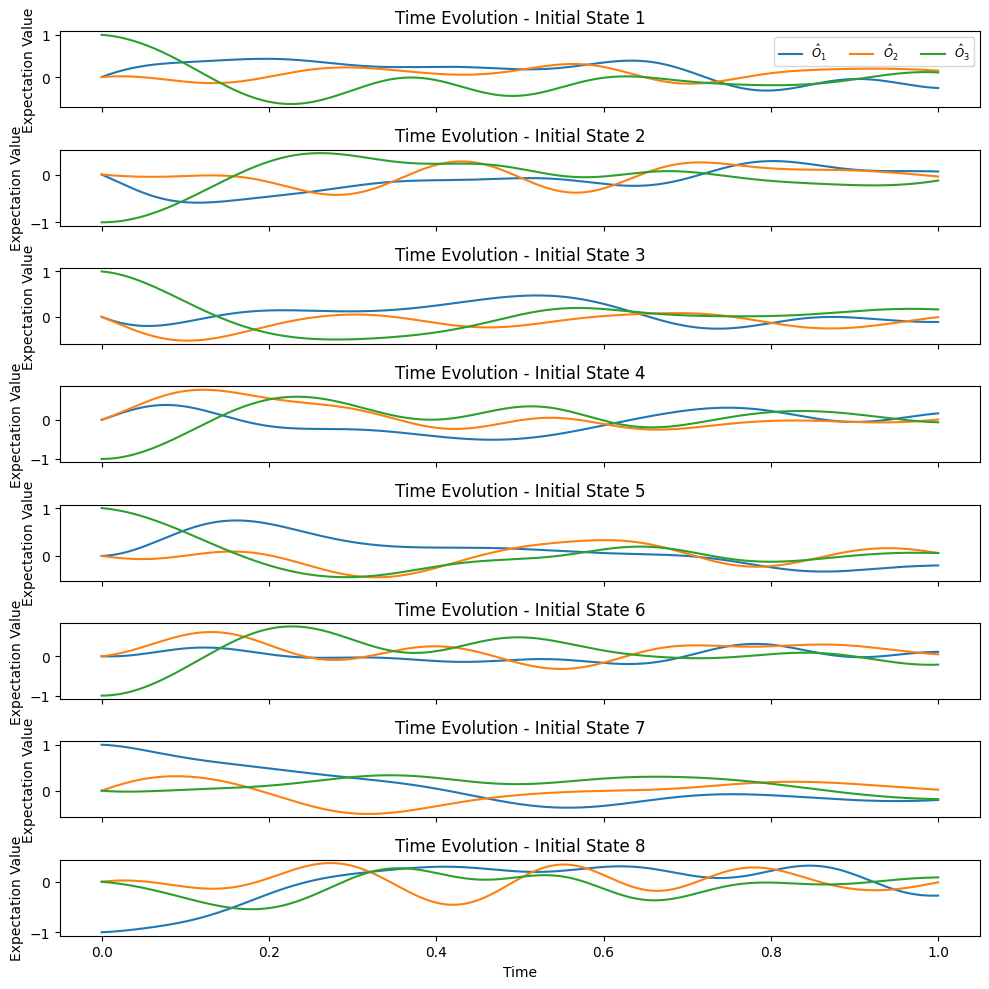

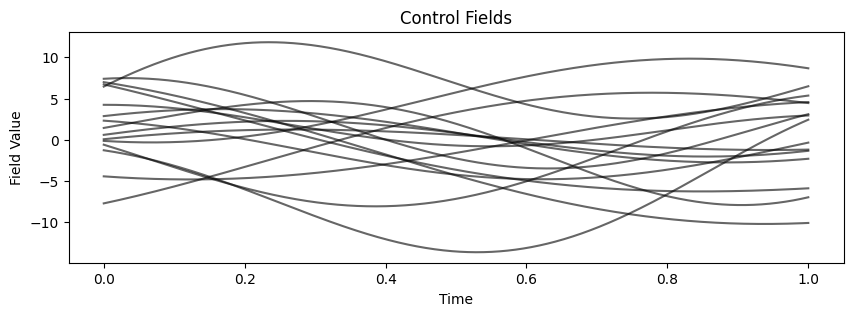

In [ ]:
SEED = 14
np.random.seed(SEED)
tc.manual_seed(SEED) 
random.seed(SEED)

# Device configuration
device = tc.device("cuda" if tc.cuda.is_available() else "cpu")

# Operadores de Pauli para cada qubit (15 Observáveis)
IX, IY, IZ = qt.tensor(qt.qeye(2), qt.sigmax()), qt.tensor(qt.qeye(2), qt.sigmay()), qt.tensor(qt.qeye(2), qt.sigmaz())
XI, YI, ZI = qt.tensor(qt.sigmax(), qt.qeye(2)), qt.tensor(qt.sigmay(), qt.qeye(2)), qt.tensor(qt.sigmaz(), qt.qeye(2))
XX, XY, XZ = qt.tensor(qt.sigmax(), qt.sigmax()), qt.tensor(qt.sigmax(), qt.sigmay()), qt.tensor(qt.sigmax(), qt.sigmaz())
YX, YY, YZ = qt.tensor(qt.sigmay(), qt.sigmax()), qt.tensor(qt.sigmay(), qt.sigmay()), qt.tensor(qt.sigmay(), qt.sigmaz())
ZX, ZY, ZZ = qt.tensor(qt.sigmaz(), qt.sigmax()), qt.tensor(qt.sigmaz(), qt.sigmay()), qt.tensor(qt.sigmaz(), qt.sigmaz())

O_op = [IX, IY, IZ, 
        XI, YI, ZI, 
        XX, XY, XZ, 
        YX, YY, YZ, 
        ZX, ZY, ZZ ]


H_op = [IX, IY, IZ, 
        XI, YI, ZI, 
        XX, XY, XZ, 
        YX, YY, YZ, 
        ZX, ZY, ZZ ]


tfinal = 1.0
N = 800
tlist = np.linspace(0.0, tfinal, N)


Js = [2*np.pi*random.uniform(-1, 1) for _ in range(9)]
dissipation = [random.uniform(0, 1) for _ in range(4)]

# Base dos estados de 1 qubit: |0>, |1>, |+>, |->, |+i>, |-i>
q0 = qt.basis(2, 0)
q1 = qt.basis(2, 1)
qx_plus = (q0 + q1).unit()
qx_minus = (q0 - q1).unit()
qy_plus = (q0 + 1j * q1).unit()
qy_minus = (q0 - 1j * q1).unit()

# Conjunto de 16 Estados Iniciais (Produtos de Pauli + Estados Emaranhados de Bell)
psi_iniciais = [
    # Produtos da base computacional / superposições
    qt.tensor(q0, q0),            # |00>
    qt.tensor(q0, q1),            # |01>
    qt.tensor(q1, q0),            # |10>
    qt.tensor(q1, q1),            # |11>
    qt.tensor(qx_plus, q0),       # |+0>
    qt.tensor(qx_plus, q1),       # |+1>
    qt.tensor(qx_plus, qx_plus),  # |++>
    qt.tensor(qx_minus, qx_minus), #,# |-- >
    qt.tensor(qy_plus, q0),       # |+i, 0>
    qt.tensor(qy_plus, qy_plus),  # |+i, +i>
    qt.tensor(qy_minus, qy_minus),# |-i, -i>
    qt.tensor(qx_plus, qy_plus)  # |+, +i>
    
    # # Estados de Bell Emaranhados (Essenciais para termos de acoplamento J_ij)
    # (qt.tensor(q0, q0) + qt.tensor(q1, q1)).unit(), # |Phi+>
    # (qt.tensor(q0, q0) - qt.tensor(q1, q1)).unit(), # |Phi->
    # (qt.tensor(q0, q1) + qt.tensor(q1, q0)).unit(), # |Psi+>
    # (qt.tensor(q0, q1) - qt.tensor(q1, q0)).unit()  # |Psi->
]

# Simulação e Armazenamento dos Resultados
lista_valor_esperado_data = []

for idx,psi0 in enumerate(psi_iniciais):
    val_data = data_qubit(Js, dissipation, tlist, O_op, H_op, fields_array, psi0, device)
    lista_valor_esperado_data.append(val_data)

# Visualização dos Primeiros 3 Estados Gerados
fig, axes = plt.subplots(8, 1, figsize=(10, 10), sharex=True)

for estado_idx in range(8):
    data_estado = lista_valor_esperado_data[estado_idx].cpu().numpy()
    for i in range(len(O_op)):
        axes[estado_idx].plot(tlist, data_estado[:, i], label=fr"$\hat{{O}}_{{{i+1}}}$" if estado_idx == 0 else "")
    
    axes[estado_idx].set_ylabel('Expectation Value')
    axes[estado_idx].set_title(f'Time Evolution - Initial State {estado_idx + 1}')

axes[0].legend(ncols=5, loc='upper right', fontsize='small')
axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

# Gráfico dos Campos de Controle
plt.figure(figsize=(10, 3))
plt.plot(tlist, fields_array[0:16,:].T, 'k-', alpha=0.6)
plt.xlabel('Time')
plt.ylabel('Field Value')
plt.title('Control Fields')
plt.show()



In [63]:

class FourierFeatures(nn.Module):
    def __init__(self, n_freq=16, f_max=3.0, trainable=False):
        super().__init__()
        # Frequências baixas e igualmente espaçadas (de 0.1*f_max até f_max)
        freqs = tc.linspace(0.1 * f_max, f_max, n_freq).unsqueeze(1) # Shape: (n_freq, 1)
        # Fixar trainable=False para impedir que o otimizador crie frequências espúrias
        self.B = nn.Parameter(freqs, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        # t: (N, 1), B: (n_freq, 1) -> x: (N, n_freq)
        x = t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            # CHAMADA CORRIGIDA AQUI:
            self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=False)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x        
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [64]:
N4=800
NUM_OBSERVAVEIS = 15  
NUM_CAMPOS = 15       
dados_esperados = [d.to(device) for d in lista_valor_esperado_data] 
NUM_ESTADOS = len(dados_esperados)             # 4 estados
IDX_DIVISAO_CAMPOS = NUM_ESTADOS * NUM_OBSERVAVEIS  # Índice 16 (0 a 15 são observáveis)

# Rede 1: Aprende as trajetórias dos observáveis
Rede_Estados = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_ESTADOS * NUM_OBSERVAVEIS,
    activation=[SIN()]*3,
    creat_p=True,
    N_of_paramater=0,
    use_fourier=True,
    n_freq=16,
    f_max=6.0
).to(device)

# Rede 2: Aprende apenas os 4 campos de controle
Rede_Campos = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_CAMPOS,
    activation=[SIN()]*3,
    creat_p=False,    
    use_fourier=True,
    n_freq=32,
    f_max=6.0
).to(device)

time =  tc.linspace(
        0,
        tfinal,
        N4,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))
time = time.to(device)




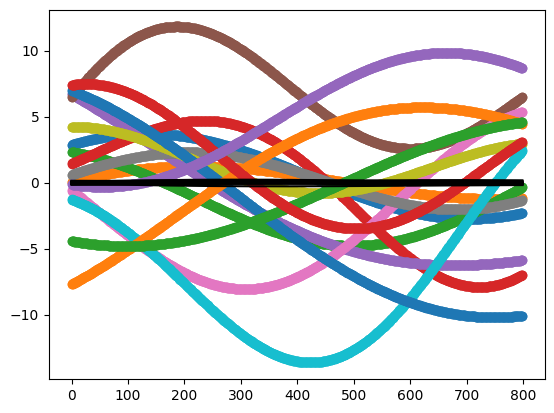

In [65]:
X_=Rede_Campos(time).cpu().detach().numpy()
plt.plot(np.transpose(fields_array[0:15,:]),'o')
for i in range(0,15):
    plt.plot(X_[:,i],"k")



plt.show()


In [66]:
def calcular_residuos_edo_15obs_full_time_dep(y_slice, dX_dt_slice, parametro, j_fields):
    IX, IY, IZ, XI, YI, ZI, XX, XY, XZ, YX, YY, YZ, ZX, ZY, ZZ = [y_slice[:, i:i+1] for i in range(15)]
    dIX, dIY, dIZ, dXI, dYI, dZI, dXX, dXY, dXZ, dYX, dYY, dYZ, dZX, dZY, dZZ = [dX_dt_slice[:, i:i+1] for i in range(15)]
    
    gamma1, gamma2, gamma3, gamma4 = parametro
    (J_IX, J_IY, J_IZ, 
     J_XI, J_YI, J_ZI, 
     J_XX, J_XY, J_XZ, 
     J_YX, J_YY, J_YZ, 
     J_ZX, J_ZY, J_ZZ) = j_fields

    loss_block = 0.0

    # Qubit 2 (Monobody Qubit 2)
    loss_block += (dIX - ( +IX*(-0.5*gamma3 - 2.0*gamma4) +IY*(-1.0*J_IZ) +IZ*(1.0*J_IY) +(-1.0*J_XZ)*XY +(1.0*J_XY)*XZ +(-1.0*J_YZ)*YY +(1.0*J_YY)*YZ +(-1.0*J_ZZ)*ZY +(1.0*J_ZY)*ZZ))**2
    loss_block += (dIY - ( +IX*(1.0*J_IZ) +IY*(-0.5*gamma3 - 2.0*gamma4) +IZ*(-1.0*J_IX) +(1.0*J_XZ)*XX +(-1.0*J_XX)*XZ +(1.0*J_YZ)*YX +(-1.0*J_YX)*YZ +(1.0*J_ZZ)*ZX +(-1.0*J_ZX)*ZZ))**2
    loss_block += (dIZ - ( +1.0*(-1.0*gamma3) +IX*(-1.0*J_IY) +IY*(1.0*J_IX) +IZ*(-1.0*gamma3) +(-1.0*J_XY)*XX +(1.0*J_XX)*XY +(-1.0*J_YY)*YX +(1.0*J_YX)*YY +(-1.0*J_ZY)*ZX +(1.0*J_ZX)*ZY))**2

    # Qubit 1 (Monobody Qubit 1)
    loss_block += (dXI - ( +XI*(-0.5*gamma1 - 2.0*gamma2) +(-1.0*J_ZI)*YI +(-1.0*J_ZX)*YX +(-1.0*J_ZY)*YY +(-1.0*J_ZZ)*YZ +(1.0*J_YI)*ZI +(1.0*J_YX)*ZX +(1.0*J_YY)*ZY +(1.0*J_YZ)*ZZ))**2
    loss_block += (dXX - ( +IY*(-1.0*J_XZ) +IZ*(1.0*J_XY) +XX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*J_IZ)*XY +(1.0*J_IY)*XZ +(-1.0*J_ZX)*YI +(-1.0*J_ZI)*YX +(1.0*J_YX)*ZI +(1.0*J_YI)*ZX))**2
    loss_block += (dXY  - ( +IX*(1.0*J_XZ) +IZ*(-1.0*J_XX) +(1.0*J_IZ)*XX +XY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*J_IX)*XZ +(-1.0*J_ZY)*YI +(-1.0*J_ZI)*YY +(1.0*J_YY)*ZI +(1.0*J_YI)*ZY))**2

    # Correlações
    loss_block += (dXZ - ( +IX*(-1.0*J_XY) +IY*(1.0*J_XX) +XI*(-1.0*gamma3) +(-1.0*J_IY)*XX +(1.0*J_IX)*XY +XZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) +(-1.0*J_ZZ)*YI +(-1.0*J_ZI)*YZ +(1.0*J_YZ)*ZI +(1.0*J_YI)*ZZ))**2
    loss_block += (dYI - ( +(1.0*J_ZI)*XI +(1.0*J_ZX)*XX +(1.0*J_ZY)*XY +(1.0*J_ZZ)*XZ +YI*(-0.5*gamma1 - 2.0*gamma2) +(-1.0*J_XI)*ZI +(-1.0*J_XX)*ZX +(-1.0*J_XY)*ZY +(-1.0*J_XZ)*ZZ))**2
    loss_block += (dYX - ( +IY*(-1.0*J_YZ) +IZ*(1.0*J_YY) +(1.0*J_ZX)*XI +(1.0*J_ZI)*XX +YX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*J_IZ)*YY +(1.0*J_IY)*YZ +(-1.0*J_XX)*ZI +(-1.0*J_XI)*ZX))**2

    loss_block += (dYY - ( +IX*(1.0*J_YZ) +IZ*(-1.0*J_YX) +(1.0*J_ZY)*XI +(1.0*J_ZI)*XY +(1.0*J_IZ)*YX +YY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*J_IX)*YZ +(-1.0*J_XY)*ZI +(-1.0*J_XI)*ZY))**2
    loss_block += (dYZ - ( +IX*(-1.0*J_YY) +IY*(1.0*J_YX) +(1.0*J_ZZ)*XI +(1.0*J_ZI)*XZ +YI*(-1.0*gamma3) +(-1.0*J_IY)*YX +(1.0*J_IX)*YY +YZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) +(-1.0*J_XZ)*ZI +(-1.0*J_XI)*ZZ))**2
    loss_block += (dZI - ( +1.0*(-1.0*gamma1) +(-1.0*J_YI)*XI +(-1.0*J_YX)*XX +(-1.0*J_YY)*XY +(-1.0*J_YZ)*XZ +(1.0*J_XI)*YI +(1.0*J_XX)*YX +(1.0*J_XY)*YY +(1.0*J_XZ)*YZ +ZI*(-1.0*gamma1)))**2

    loss_block += (dZX  - ( +IX*(-1.0*gamma1) +IY*(-1.0*J_ZZ) +IZ*(1.0*J_ZY) +(-1.0*J_YX)*XI +(-1.0*J_YI)*XX +(1.0*J_XX)*YI +(1.0*J_XI)*YX +ZX*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*J_IZ)*ZY +(1.0*J_IY)*ZZ))**2
    loss_block += (dZY- ( +IX*(1.0*J_ZZ) +IY*(-1.0*gamma1) +IZ*(-1.0*J_ZX) +(-1.0*J_YY)*XI +(-1.0*J_YI)*XY +(1.0*J_XY)*YI +(1.0*J_XI)*YY +(1.0*J_IZ)*ZX +ZY*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*J_IX)*ZZ))**2
    loss_block += (dZZ - ( +IX*(-1.0*J_ZY) +IY*(1.0*J_ZX) +IZ*(-1.0*gamma1) +(-1.0*J_YZ)*XI +(-1.0*J_YI)*XZ +(1.0*J_XZ)*YI +(1.0*J_XI)*YZ +ZI*(-1.0*gamma3) +(-1.0*J_IY)*ZX +(1.0*J_IX)*ZY +ZZ*(-1.0*gamma1 - 1.0*gamma3)))**2

    return loss_block

In [67]:
import torch as tc
import numpy as np
from scipy.interpolate import CubicSpline


# ==============================================================================
# ESTÁGIO 1 & 2: Derivadas Analíticas Ultra-Suaves via Splines Cúbicas
# ==============================================================================
print("Calculando derivadas analíticas ultra-suaves via Spline Cúbica...")

t_np = time.squeeze().detach().cpu().numpy()
y_spline_list = []
dY_dt_spline_list = []

for s in range(NUM_ESTADOS):
    # Dados do QuTiP para o estado s
    y_real_np = dados_esperados[s].cpu().numpy() # Shape: (N, 15)
    
    # Ajusta Spline Cúbica ponto a ponto
    cs = CubicSpline(t_np, y_real_np, axis=0)
    
    # Avalia a spline e sua derivada analítica exata (nu=1)
    y_smooth = cs(t_np)
    dy_dt_smooth = cs(t_np, nu=1)
    
    y_spline_list.append(tc.tensor(y_smooth, dtype=tc.float32, device=device))
    dY_dt_spline_list.append(tc.tensor(dy_dt_smooth, dtype=tc.float32, device=device))

y_fixo_spline = tc.cat(y_spline_list, dim=1)        # Shape: (N, 240)
dX_dt_fixo_spline = tc.cat(dY_dt_spline_list, dim=1) # Shape: (N, 240)

print("Derivadas calculadas! Iniciando otimização da Rede_Campos...")

# ==============================================================================
# ESTÁGIO 3: Otimizar APENAS a Rede_Campos com Derivadas da Spline
# ==============================================================================
opt_campos = tc.optim.Adam(Rede_Campos.parameters(), lr=1e-3)
scheduler_cam = tc.optim.lr_scheduler.ReduceLROnPlateau(opt_campos, mode='min', factor=0.5, patience=200)

param_qutip = tc.tensor([0.0, 0.0, 0.0, 0.0], device=device) # Gammas fixos em 0

for epoca in range(1000):
    opt_campos.zero_grad()
    
    # Rede de campos prevê J(t)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(15)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        # Usa os estados e derivadas SUAVES da Spline
        y_cond = y_fixo_spline[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo_spline[:, idx_start:idx_end]

        residuos = calcular_residuos_edo_15obs_full_time_dep(y_cond, dX_dt_cond, param_qutip, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS

    loss_edo.backward()
    opt_campos.step()
    scheduler_cam.step(loss_edo)

    if (epoca + 1) % 500 == 0:
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e}")


Calculando derivadas analíticas ultra-suaves via Spline Cúbica...
Derivadas calculadas! Iniciando otimização da Rede_Campos...
Época 500 | Loss EDO: 3.16e+00
Época 1000 | Loss EDO: 3.14e+00


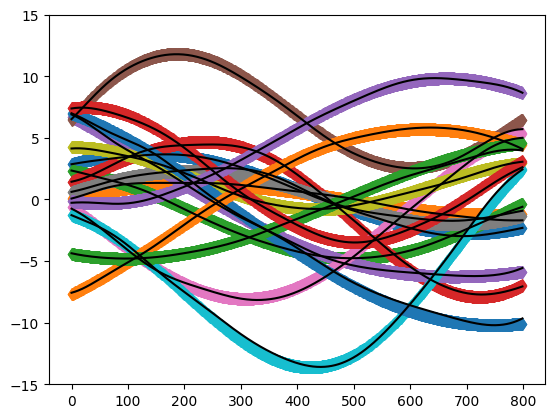

tensor([0., 0., 0., 0.], device='cuda:0')


In [68]:
X_=Rede_Campos(time).cpu().detach().numpy()
plt.plot(np.transpose(fields_array[0:16,:]),'d')
for i in range(15):
    plt.plot(X_[:,i],"k")
plt.ylim(-15,15)


plt.show()
print(param_qutip)


In [69]:
import torch as tc
import numpy as np

# ==============================================================================
# FASE 3A: Otimizar APENAS os Gammas (Rede_Campos CONGELADA)
# ==============================================================================
# param_gamma = -5.0 resulta em softplus(-5.0) ~ 0.0067 (próximo de zero)
param_gamma = tc.nn.Parameter(tc.tensor([-5.0, -5.0, -5.0, -5.0], device=device))

opt_gamma = tc.optim.Adam([param_gamma], lr=1e-2)

# Hiperparâmetro L1: empurrar os gammas para zero quando desnecessários
lambda_l1 = 0e-3 

print("Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...")
for epoca in range(1000):
    opt_gamma.zero_grad()
    
    gammas_positivos = tc.nn.functional.softplus(param_gamma)
    
    # Avalia a Rede_Campos sem calcular gradientes para ela
    with tc.no_grad():
        z = Rede_Campos(time)
        j_fields = [z[:, i:i+1] for i in range(15)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo_spline[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo_spline[:, idx_start:idx_end]

        residuos = calcular_residuos_edo_15obs_full_time_dep(y_cond, dX_dt_cond, gammas_positivos, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    
    # Perda Total com Regularização L1 nos Gammas
    loss_total = loss_edo + lambda_l1 * tc.sum(gammas_positivos)
    
    loss_total.backward()
    opt_gamma.step()

    if (epoca + 1) % 200 == 0:
        g_est = tc.nn.functional.softplus(param_gamma).detach().cpu().numpy()
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

# ==============================================================================
# FASE 3B: Refinamento Concomitante Fino (Campos + Gammas)
# ==============================================================================
opt_conjunto = tc.optim.Adam([
    {'params': Rede_Campos.parameters(), 'lr': 1e-5}, # LR reduzido para proteger os campos
    {'params': [param_gamma],            'lr': 1e-3}
])

print("\nFase 3B: Otimização Concomitante Final...")
for epoca in range(2000):
    opt_conjunto.zero_grad()
    
    gammas_positivos = tc.nn.functional.softplus(param_gamma)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(15)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo_spline[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo_spline[:, idx_start:idx_end]

        residuos = calcular_residuos_edo_15obs_full_time_dep(y_cond, dX_dt_cond, gammas_positivos, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    loss_total = loss_edo + lambda_l1 * tc.sum(gammas_positivos)
    
    loss_total.backward()
    opt_conjunto.step()

    if (epoca + 1) % 500 == 0:
        g_est = tc.nn.functional.softplus(param_gamma).detach().cpu().numpy()
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...
Época 200 | Loss EDO: 1.86e+00 | Gammas Estimados: [0.12105 0.11904 0.12179 0.11659]
Época 400 | Loss EDO: 1.91e-01 | Gammas Estimados: [0.59774 0.38936 0.69006 0.18122]
Época 600 | Loss EDO: 1.89e-01 | Gammas Estimados: [0.60427 0.40522 0.69726 0.14769]
Época 800 | Loss EDO: 1.88e-01 | Gammas Estimados: [0.6052  0.4088  0.69844 0.14067]
Época 1000 | Loss EDO: 1.88e-01 | Gammas Estimados: [0.6054  0.40951 0.69869 0.13922]

Fase 3B: Otimização Concomitante Final...
Época 500 | Loss EDO: 1.45e-02 | Gammas Estimados: [0.67392 0.39656 0.76441 0.12472]
Época 1000 | Loss EDO: 5.17e-03 | Gammas Estimados: [0.68041 0.3963  0.77239 0.12125]
Época 1500 | Loss EDO: 2.61e-03 | Gammas Estimados: [0.68223 0.39632 0.77495 0.11999]
Época 2000 | Loss EDO: 1.48e-03 | Gammas Estimados: [0.683   0.39634 0.77613 0.11941]


[0.6842331280769555, 0.39667364503301394, 0.7775165878901124, 0.11839956986543854]


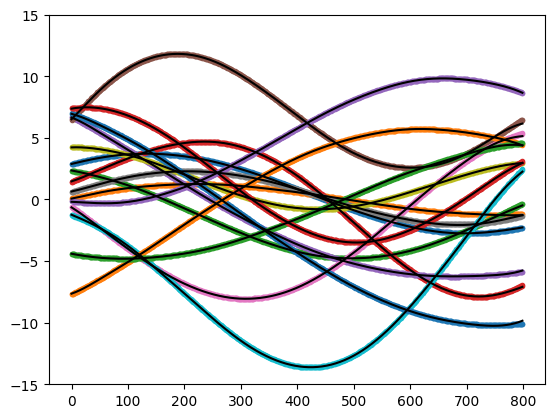

In [70]:
print(dissipation)
X_=Rede_Campos(time).cpu().detach().numpy()
plt.plot(np.transpose(fields_array[0:16,:]),'.')
for i in range(15):
    plt.plot(X_[:,i],"k")
plt.ylim(-15,15)


plt.show()


In [71]:
import numpy as np
import torch as tc
import qutip as qt
from scipy.interpolate import CubicSpline

# ==============================================================================
# 1. CONFIGURAÇÃO DOS OPERADORES E DA SIMULAÇÃO NO QUTIP
# ==============================================================================
I = qt.qeye(2)
X = qt.sigmax()
Y = qt.sigmay()
Z = qt.sigmaz()
sm = qt.sigmam() # Operador de aniquilação (para amplitude damping)

# Lista ordenada dos 15 observáveis
obs_list = [
    qt.tensor(I, X), qt.tensor(I, Y), qt.tensor(I, Z),  # IX, IY, IZ
    qt.tensor(X, I), qt.tensor(Y, I), qt.tensor(Z, I),  # XI, YI, ZI
    qt.tensor(X, X), qt.tensor(X, Y), qt.tensor(X, Z),  # XX, XY, XZ
    qt.tensor(Y, X), qt.tensor(Y, Y), qt.tensor(Y, Z),  # YX, YY, YZ
    qt.tensor(Z, X), qt.tensor(Z, Y), qt.tensor(Z, Z)   # ZX, ZY, ZZ
]

# 2. DEFINIÇÃO DOS 15 CAMPOS J_k(t) CONHECIDOS (Funções de teste)
# Criamos funções temporais senoidais/cossenoidais arbitrárias para cada J
t_eval = np.linspace(0, 5, 1000)

def j_funcs(t):
    return [
        0.5 * np.sin(1.0 * t),  # J_IX
        0.3 * np.cos(1.2 * t),  # J_IY
        0.8 * np.sin(0.5 * t),  # J_IZ
        0.4 * np.cos(0.8 * t),  # J_XI
        0.6 * np.sin(1.5 * t),  # J_YI
        0.2 * np.cos(2.0 * t),  # J_ZI
        1.0 * np.sin(0.7 * t),  # J_XX
        0.5 * np.cos(1.1 * t),  # J_XY
        0.3 * np.sin(0.9 * t),  # J_XZ
        0.7 * np.cos(1.3 * t),  # J_YX
        0.9 * np.sin(0.4 * t),  # J_YY
        0.2 * np.cos(1.7 * t),  # J_YZ
        0.6 * np.sin(0.6 * t),  # J_ZX
        0.4 * np.cos(1.4 * t),  # J_ZY
        0.8 * np.sin(1.8 * t)   # J_ZZ
    ]

# Monta o Hamiltoniano do QuTiP: H(t) = 0.5 * sum_k J_k(t) * O_k
H = []
for k in range(15):
    # Passamos a função temporal individual para o QuTiP
    def make_j_func(idx):
        return lambda t, args: 0.5 * j_funcs(t)[idx]
    H.append([obs_list[k], make_j_func(k)])

# 3. DISSIPAÇÃO DO QUTIP
gamma1, gamma2, gamma3, gamma4 = 0.05, 0.02, 0.08, 0.01

c_ops = [
    np.sqrt(gamma1) * qt.tensor(sm, I), # Qubit 1: Amplitude Damping
    np.sqrt(gamma2) * qt.tensor(Z, I),  # Qubit 1: Dephasing
    np.sqrt(gamma3) * qt.tensor(I, sm), # Qubit 2: Amplitude Damping
    np.sqrt(gamma4) * qt.tensor(I, Z)   # Qubit 2: Dephasing
]

# Estado inicial arbitrário (ex: |00>)
psi0 = qt.tensor(qt.basis(2, 0), qt.basis(2, 0))

# Resolve a Equação Mestra de Lindblad
result = qt.mesolve(H, psi0, t_eval, c_ops, e_ops=obs_list)

# Matriz de observáveis Y do QuTiP: Shape (1000, 15)
y_qutip = np.array(result.expect).T

# ==============================================================================
# 2. CÁLCULO DAS DERIVADAS ANALÍTICAS VIA SPLINE CÚBICA
# ==============================================================================
splines = [CubicSpline(t_eval, y_qutip[:, i]) for i in range(15)]

# Matriz de derivadas dy/dt: Shape (1000, 15)
dy_dt_spline = np.array([spl(t_eval, nu=1) for spl in splines]).T

# Avalia os campos J(t) nos mesmos instantes de tempo: Shape (15, 1000)
j_eval = np.array(j_funcs(t_eval)) # List de 15 arrays de tamanho 1000

# ==============================================================================
# 3. VALIDAÇÃO NA SUA FUNÇÃO DE RESÍDUO
# ==============================================================================
# Converte tudo para Tensores do PyTorch
y_tensor = tc.tensor(y_qutip, dtype=tc.float32)
dy_dt_tensor = tc.tensor(dy_dt_spline, dtype=tc.float32)
param_tensor = tc.tensor([gamma1, gamma2, gamma3, gamma4], dtype=tc.float32)

# Transforma j_eval numa lista de 15 tensores com shape (1000, 1)
j_fields_tensor = [tc.tensor(j_eval[i:i+1].T, dtype=tc.float32) for i in range(15)]

# Executa a sua função
residuos_quadrados = calcular_residuos_edo_15obs_full_time_dep(
    y_slice=y_tensor,
    dX_dt_slice=dy_dt_tensor,
    parametro=param_tensor,
    j_fields=j_fields_tensor
)

loss_medio = residuos_quadrados.mean().item()
loss_maximo = residuos_quadrados.max().item()

print("="*60)
print(f"Resultado do Teste de Concordância com o QuTiP:")
print(f"Resíduo Médio Quadrático : {loss_medio:.2e}")
print(f"Resíduo Máximo Pontual   : {loss_maximo:.2e}")
print("="*60)

if loss_medio < 1e-5:
    print("Sucesso! A função de resíduos reflete perfeitamente a física do QuTiP.")
else:
    print("Atenção: Existe uma discrepância de equações ou de sinais a ser corrigida.")

print(qt.destroy(2))
print(qt.sigmam())

Resultado do Teste de Concordância com o QuTiP:
Resíduo Médio Quadrático : 1.09e-11
Resíduo Máximo Pontual   : 1.31e-10
Sucesso! A função de resíduos reflete perfeitamente a física do QuTiP.
Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=Dia, isherm=False
Qobj data =
[[0. 1.]
 [0. 0.]]
Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=CSR, isherm=False
Qobj data =
[[0. 0.]
 [1. 0.]]
